# The deuteron with VQE: ansatzes and qubit mappings

## The problem

The deuteron is the nucleus of heavy hydrogen: one proton and one neutron bound together. It is the simplest nucleus there is, and the simplest quantum many-body system in nuclear physics. What is its **ground-state energy**? The measured value is $-2.2246$ MeV: that much energy must be added to pull the two particles apart. This is the **binding energy**.

We use the setup of the first quantum computation of a nucleus (Dumitrescu et al., *Phys. Rev. Lett.* **120**, 210501 (2018)). Two ideas make the problem small enough for a few qubits:

- **Separate the motion.** In the frame that moves with the deuteron, the problem is one particle (of reduced mass) in a potential. The ground state has no angular momentum (an S wave).
- **Use a contact force.** The deuteron is large compared with the range of the nuclear force, so at this scale the force looks like a delta function: the particles feel each other only when they are on top of each other. This is the **pionless effective field theory**.

We find the ground state with the **variational quantum eigensolver (VQE)**: a classical optimizer tunes the angles of a circuit (the **ansatz**) to minimize the energy of the state it prepares. Two choices decide whether that works:

- the **mapping**: how the basis states of the deuteron are stored in qubits, which changes the number of qubits and the Pauli terms of the Hamiltonian;
- the **ansatz**: the family of states the circuit can reach.

This notebook runs every combination in the same optimization loop and compares them.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | Build the deuteron Hamiltonian and map it to qubits | `ops.py` |
| 2. Encoding | Build the ansatzes | `encoding.py` |
| 3. Execution | Run the VQE loop for every pair | `execution.py` |
| 4. Analysis | Compare errors, cost and convergence | `analysis.py` |

The same steps run from the command line with `python deuteron/main.py`. The code lives in `../scripts/deuteron/` and is imported below, so you can read it next to the notebook. Energies are in MeV.

## Setup

By default this notebook runs on the Aer simulator with **exact energies** (no shot noise), so the differences you see come from the mapping and the ansatz alone. Set `shots` to a number such as `4096` to add sampling noise.

- `n_states`: how many oscillator states the basis holds. It must be a power of two. More states is a better approximation of the deuteron and a larger circuit.
- `reps`: layers of the hardware-efficient ansatzes. `starts`: random starting points for the optimizer. `maxiter`: optimizer budget per start.
- `backend_name`: leave `None` for the simulator. A hardware run needs `shots > 0`, and it submits many jobs, so try one mapping and one ansatz first.

In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

# The deuteron code lives in ../scripts/deuteron.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/deuteron").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

n_states = 8  # oscillator states in the basis (power of two)
backend_name = None  # None = Aer simulator
reps = 2
starts = 3
maxiter = 500
shots = 0  # 0 = exact energies (simulator only)

## Step 1: The operator (the Hamiltonian)

### From the deuteron to a matrix

We write the relative wave function as a mix of the S-wave states $|n\rangle$, $n=0,1,2,\dots$ of a three-dimensional **harmonic oscillator** of spacing $\hbar\omega = 7$ MeV. These states are a convenient basis, not the physics: the oscillator is a tool, and the deuteron is not trapped in one. In this basis

$$\langle n|T|n\rangle = \tfrac{\hbar\omega}{2}\left(2n+\tfrac32\right),\qquad \langle n|T|n+1\rangle = -\tfrac{\hbar\omega}{2}\sqrt{(n+1)\left(n+\tfrac32\right)},\qquad \langle n|V|n'\rangle = -V_0\,\delta_{n0}\delta_{n'0},$$

with $V_0 = 5.687$ MeV. The kinetic energy $T$ connects each state to its neighbors only, and, as in the paper, the contact force $V$ is taken to act on $|0\rangle$ alone (a simplification of the delta function). So the Hamiltonian is a **tridiagonal matrix** with one extra number in the corner. The strength $V_0$ is chosen so that a large basis gives an energy close to the measured one, then fixed and kept for every basis size below.

Keeping only the first $N$ states is a **truncation**. A larger $N$ resolves the wave function better, so the lowest eigenvalue should approach the real deuteron energy as $N$ grows.

In [2]:
np.set_printoptions(precision=3, suppress=True, linewidth=120)
print(f"Hamiltonian in {n_states} oscillator states (MeV):")
print(ops.basis_hamiltonian(n_states))

exact = ops.exact_energies(n_states)
print(f"\nExact energy in this basis   {exact['exact']:.6f} MeV")
print(f"Reference |0> alone          {exact['ref']:.6f} MeV")
print(f"Infinite-basis energy        {exact['converged']:.6f} MeV")
print(f"Measured                     {exact['experiment']:.6f} MeV")

Hamiltonian in 8 oscillator states (MeV):
[[ -0.437  -4.287   0.      0.      0.      0.      0.      0.   ]
 [ -4.287  12.25   -7.826   0.      0.      0.      0.      0.   ]
 [  0.     -7.826  19.25  -11.341   0.      0.      0.      0.   ]
 [  0.      0.    -11.341  26.25  -14.849   0.      0.      0.   ]
 [  0.      0.      0.    -14.849  33.25  -18.354   0.      0.   ]
 [  0.      0.      0.      0.    -18.354  40.25  -21.857   0.   ]
 [  0.      0.      0.      0.      0.    -21.857  47.25  -25.36 ]
 [  0.      0.      0.      0.      0.      0.    -25.36   54.25 ]]

Exact energy in this basis   -2.215038 MeV
Reference |0> alone          -0.436581 MeV
Infinite-basis energy        -2.221225 MeV
Measured                     -2.224575 MeV


The reference state $|0\rangle$ alone gets only $-0.44$ MeV: the contact attraction ($-V_0$) is mostly cancelled by the oscillator's zero-point energy, $\tfrac34\hbar\omega = 5.25$ MeV. The deuteron is bound because the wave function **mixes in higher oscillator states**, which lowers the kinetic energy. The gap between the two numbers is what the quantum computer has to find.

How big a basis do we need? The eigenvalue of the truncated matrix is an upper bound on the infinite-basis answer (a basis of $N+1$ states contains the basis of $N$), so it can only go down as $N$ grows.

In [3]:
print(f"{'N':>4} {'qubits (binary)':>16} {'ground energy (MeV)':>20} {'error vs infinite basis (keV)':>30}")
infinite = ops.ground_energy(256)
for n in (1, 2, 3, 4, 8, 16, 32, 64):
    e = ops.ground_energy(n)
    q = f"{int(np.log2(n))}" if n > 1 and n & (n - 1) == 0 else "-"
    print(f"{n:>4} {q:>16} {e:>20.5f} {1e3 * (e - infinite):>30.1f}")

   N  qubits (binary)  ground energy (MeV)  error vs infinite basis (keV)
   1                -             -0.43658                         1784.6
   2                1             -1.74916                          472.1
   3                -             -2.04567                          175.6
   4                2             -2.14398                           77.2
   8                3             -2.21504                            6.2
  16                4             -2.22106                            0.2
  32                5             -2.22122                            0.0
  64                6             -2.22123                            0.0


Four states is already within 0.08 MeV and eight within 0.006 MeV of the infinite-basis value. Because the basis states are stored in binary below, **doubling $N$ costs only one more qubit**. That logarithmic growth is the reason this problem is a good fit for a quantum computer. (The small remaining difference between the infinite-basis value $-2.2212$ MeV and the measured $-2.2246$ MeV is the physics the contact model leaves out.)

### From states to qubits: the mapping

A register of $q$ qubits has $2^q$ basis states, and we must decide which qubit state stands for which oscillator state $|n\rangle$. This choice is the **qubit mapping**. Each mapping gives a different Pauli-string Hamiltonian with the **same eigenvalues**:

| Mapping | Qubit state for $|n\rangle$ | Qubits for $N$ states |
|---|---|---|
| Binary (`binary`) | the bits of $n$ | $\log_2 N$ |
| Gray (`gray`) | the Gray code of $n$, so $n$ and $n+1$ differ in one bit | $\log_2 N$ |
| Unary (`unary`) | only qubit $n$ is 1 ("one-hot") | $N$ |

The kinetic energy connects $n$ with $n+1$. In Gray code those two states differ by one bit, so each hop is a single-qubit flip. In unary each hop moves a single excitation to the neighboring qubit.

In [4]:
for mapping in ops.MAPPINGS:
    H = ops.build_hamiltonian(n_states, mapping)
    weights = [sum(c != "I" for c in label) for label in H.paulis.to_labels()]
    energies = np.linalg.eigvalsh(H.to_matrix())
    print(
        f"{mapping:>7}: {H.num_qubits} qubits, {len(H):>2} Pauli terms, "
        f"max weight {max(weights)}, lowest energy {energies[0]:.6f} MeV, "
        f"next {energies[1]:.3f} MeV"
    )

print("\nThe 2-qubit binary Hamiltonian (N = 4) in full:")
print(ops.build_hamiltonian(4, "binary"))

 binary: 3 qubits, 20 Pauli terms, max weight 3, lowest energy -2.215038 MeV, next 2.522 MeV
   gray: 3 qubits, 20 Pauli terms, max weight 3, lowest energy -2.215038 MeV, next 2.522 MeV


  unary: 8 qubits, 23 Pauli terms, max weight 2, lowest energy -2.215038 MeV, next 0.000 MeV

The 2-qubit binary Hamiltonian (N = 4) in full:
SparsePauliOp(['II', 'IX', 'IZ', 'XX', 'YY', 'ZI', 'ZX', 'ZZ'],
              coeffs=[14.328+0.j, -7.814+0.j, -4.922+0.j, -3.913+0.j, -3.913+0.j, -8.422+0.j,  3.527+0.j, -1.422+0.j])


## Stop and think: what is a "different Hamiltonian"?

1. **Same physics, same spectrum.** Every row prints the same lowest energy. A mapping is only a relabeling of basis states, so nothing about the deuteron changes.
2. **What does change is the circuit cost and the landscape.** The number of qubits, the number of Pauli terms (each one is a measurement setting) and the weight of the terms (long strings need long chains of CX gates) all depend on the mapping. Step 3 shows that they also change how easily an optimizer finds the minimum.
3. **Binary and unary trade qubits for term weight.** Binary uses the fewest qubits but has terms that act on all of them (a long Pauli string for the hop from $|3\rangle=011$ to $|4\rangle=100$). Unary needs $N$ qubits but every term acts on at most two.
4. **Unary has states that are not oscillator states.** With 8 qubits there are 256 states, and only 8 of them have a single excitation. The rest (no excitation, two excitations, and so on) mean nothing for the deuteron. The unary Hamiltonian gives them energies of their own: $0$ for no excitation, the sum of two oscillator energies for two. None of these is below the ground state, so the minimum is still the right one, but an ansatz that does not conserve the number of excitations can wander into them. The printed "next" energy of the unary row, $0$, is the empty register.

## Step 2: Encoding and ansatzes

An ansatz $|\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)|\text{start}\rangle$ defines which states the optimizer can reach. By the **variational principle**, $\langle\psi|H|\psi\rangle \ge E_0$ for every state, so the lowest energy the optimizer finds is an upper bound on the truth. A better ansatz gets closer.

We compare four, ordered from most to least knowledge of the problem:

| Ansatz | Idea | Angles (binary / unary, $N=8$) |
|---|---|---|
| `ref` | The state $|0\rangle$. No angles. The baseline. | 0 / 0 |
| `rot` | $|0\rangle$ followed by a chain of rotations $e^{\theta_k G_k}$ that move amplitude from $|k\rangle$ to $|k+1\rangle$. | 7 / 7 |
| `hea` | **Hardware-efficient**: layers of $R_Y$ and CX, starting from $|0\ldots0\rangle$. No knowledge of the basis. | 9 / 24 |
| `hea_ref` | The same, starting from the state $|0\rangle$. | 9 / 24 |

The wave function of this Hamiltonian is a real vector with $N$ components. Rotating $|0\rangle$ into $|1\rangle$ by $\theta_0$, then part of $|1\rangle$ into $|2\rangle$ by $\theta_1$, and so on, are the **spherical coordinates** of such a vector, so `rot` with $N-1$ angles can reach every real state, including the ground state. It is exact by construction, the analog of a chemistry ansatz that contains the answer.

The rotations are built from the matrices $G_k$ in `ops.py`, so the same code works in every mapping. The first thing to check is that the reference state is prepared correctly: its energy must match the value above in every mapping.

In [5]:
from qiskit.quantum_info import Statevector

for mapping in ops.MAPPINGS:
    H = ops.build_hamiltonian(n_states, mapping)
    ref = enc.ref_state(n_states, mapping)
    e = Statevector(ref).expectation_value(H).real
    print(f"{mapping:>7}: |0> is bitstring {ops.ref_bits(n_states, mapping)}, <H> = {e:.6f} MeV")

 binary: |0> is bitstring 000, <H> = -0.436581 MeV
   gray: |0> is bitstring 000, <H> = -0.436581 MeV
  unary: |0> is bitstring 00000001, <H> = -0.436581 MeV


Rotation chain with 4 states in the binary mapping (2 qubits):


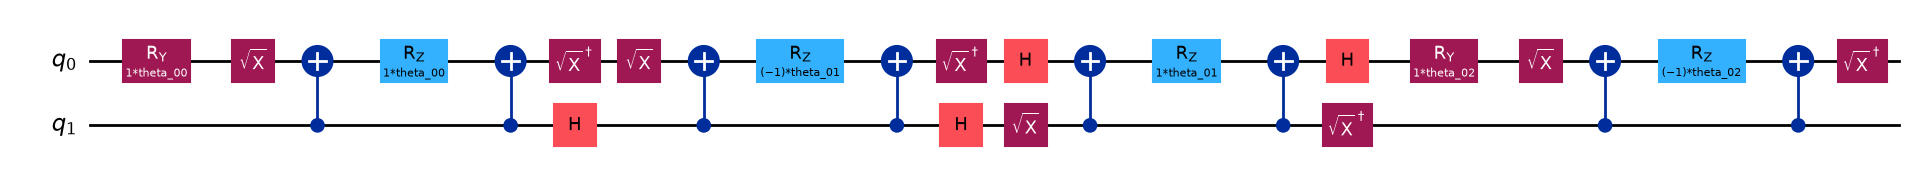

HEA with 4 states in the binary mapping (2 qubits):


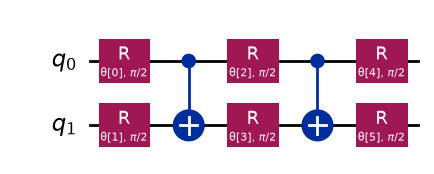

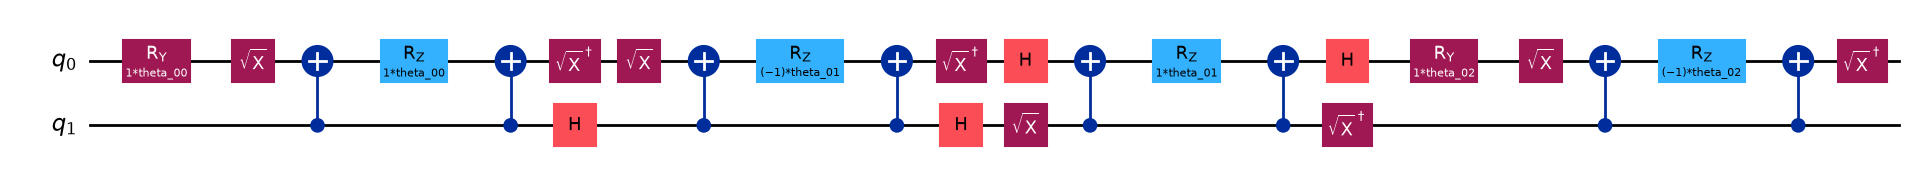

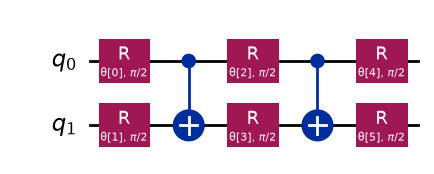

In [6]:
for name in ["rot", "hea"]:
    print(enc.LABELS[name], "with 4 states in the binary mapping (2 qubits):")
    display(enc.build_ansatz(name, 4, "binary", reps).decompose().draw("mpl", fold=-1))

In [7]:
# Circuit cost after compiling to {RZ, SX, X, CX}, per ansatz and mapping.
print(f"{'':>7}" + "".join(f"{a:>14}" for a in enc.ANSATZES))
for mapping in ops.MAPPINGS:
    cells = []
    for name in enc.ANSATZES:
        c = enc.build_ansatz(name, n_states, mapping, reps)
        depth, cx = enc.circuit_cost(c)
        cells.append(f"{cx:>3} CX, d={depth:<3}")
    print(f"{mapping:>7}" + "".join(f"{x:>14}" for x in cells))

                  ref           rot           hea       hea_ref


 binary   0 CX, d=0    68 CX, d=174   4 CX, d=16    4 CX, d=16 
   gray   0 CX, d=0    50 CX, d=92    4 CX, d=16    4 CX, d=16 
  unary   0 CX, d=1    28 CX, d=121  14 CX, d=21   14 CX, d=23 


## Stop and think: what did the encoding decide?

1. **The mapping changes the cost of `rot`.** Each rotation is an evolution under a few Pauli strings. In binary, the hop from $|3\rangle=011$ to $|4\rangle=100$ flips all three qubits and the rotation needs a long ladder of CX gates. In Gray code neighbors differ in a single bit, so the strings are shorter. In unary every rotation acts on two qubits.
2. **`hea` is shallow and fixed.** Its shape does not depend on the problem. On noisy hardware that matters, and it is why `hea` is popular despite its drawbacks.
3. **The ansatz must be able to express the answer.** `ref` cannot: it is a single basis state. `rot` can, with $N-1$ angles. `hea` can in principle (given enough layers), but nothing in its structure points toward it.
4. **`hea` does not know about excitations.** In the unary mapping its starting state $|0\ldots0\rangle$ is the empty register, which is not an oscillator state at all, and nothing keeps it in the single-excitation sector. `hea_ref` starts in the right place but its gates can still leave. In the binary and Gray mappings, $|0\rangle$ is the qubit state $|0\ldots0\rangle$, so `hea` and `hea_ref` are the same circuit and give the same numbers.

## Step 3: Execution

Each iteration of the VQE loop:

1. The classical optimizer (**COBYLA**) proposes angles $\boldsymbol\theta$.
2. The **Estimator** prepares $|\psi(\boldsymbol\theta)\rangle$ and returns $\langle H\rangle$.
3. The optimizer lowers $\langle H\rangle$ and repeats.

Every (mapping, ansatz) pair gets the same budget (`starts` random starting points, `maxiter` iterations each) and the same random seed, so that differences come from the pair and not from the settings. `ref` has no angles and is evaluated once. With exact energies the full table takes about a minute on the simulator.

In [8]:
data = execution.run(
    n_states,
    ops.MAPPINGS,
    enc.ANSATZES,
    backend_name,
    reps=reps,
    starts=starts,
    shots=shots,
    maxiter=maxiter,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

8 oscillator states: exact energy -2.215038 MeV, reference |0> -0.436581 MeV
    binary     ref: error +1.78e+00 MeV (0 angles, 1 evaluations)


    binary     rot: error +8.48e-03 MeV (7 angles, 1500 evaluations)


    binary     hea: error +2.26e-03 MeV (9 angles, 1500 evaluations)


    binary hea_ref: error +2.26e-03 MeV (9 angles, 1500 evaluations)
      gray     ref: error +1.78e+00 MeV (0 angles, 1 evaluations)


      gray     rot: error +7.74e-03 MeV (7 angles, 1500 evaluations)


      gray     hea: error +3.51e-02 MeV (9 angles, 1500 evaluations)


      gray hea_ref: error +3.51e-02 MeV (9 angles, 1500 evaluations)
     unary     ref: error +1.78e+00 MeV (0 angles, 1 evaluations)


     unary     rot: error +2.09e-04 MeV (7 angles, 1500 evaluations)


     unary     hea: error +1.40e+00 MeV (24 angles, 1500 evaluations)


     unary hea_ref: error +1.52e+00 MeV (24 angles, 1500 evaluations)

Total time: 70 s


## Step 4: Analysis

Each row is one pair. The **error** is the energy found minus the exact energy in this basis, so it is never negative (except for shot noise). `*` marks results within 10 keV, half a percent of the binding energy. Then two views: convergence (error of the best restart against evaluations, one panel per mapping) and the final errors.


Deuteron in 8 oscillator states on aer_simulator, exact energies
Exact energy in this basis:  -2.215038 MeV
Reference |0> energy:        -0.436581 MeV
Infinite-basis energy:       -2.221225 MeV
Measured binding energy:     -2.224575 MeV

 mapping  ansatz qubits terms angles   CX depth  evals  error (keV)
  binary     ref      3    20      0    0     0      1    1778.457 
  binary     rot      3    20      7   68   174   1500       8.482*
  binary     hea      3    20      9    4    16   1500       2.256*
  binary hea_ref      3    20      9    4    16   1500       2.256*
    gray     ref      3    20      0    0     0      1    1778.457 
    gray     rot      3    20      7   50    92   1500       7.737*
    gray     hea      3    20      9    4    16   1500      35.058 
    gray hea_ref      3    20      9    4    16   1500      35.058 
   unary     ref      8    23      0    0     1      1    1778.457 
   unary     rot      8    23      7   28   121   1500       0.209*
   unary     


Saved /tmp/deuteron_result.png


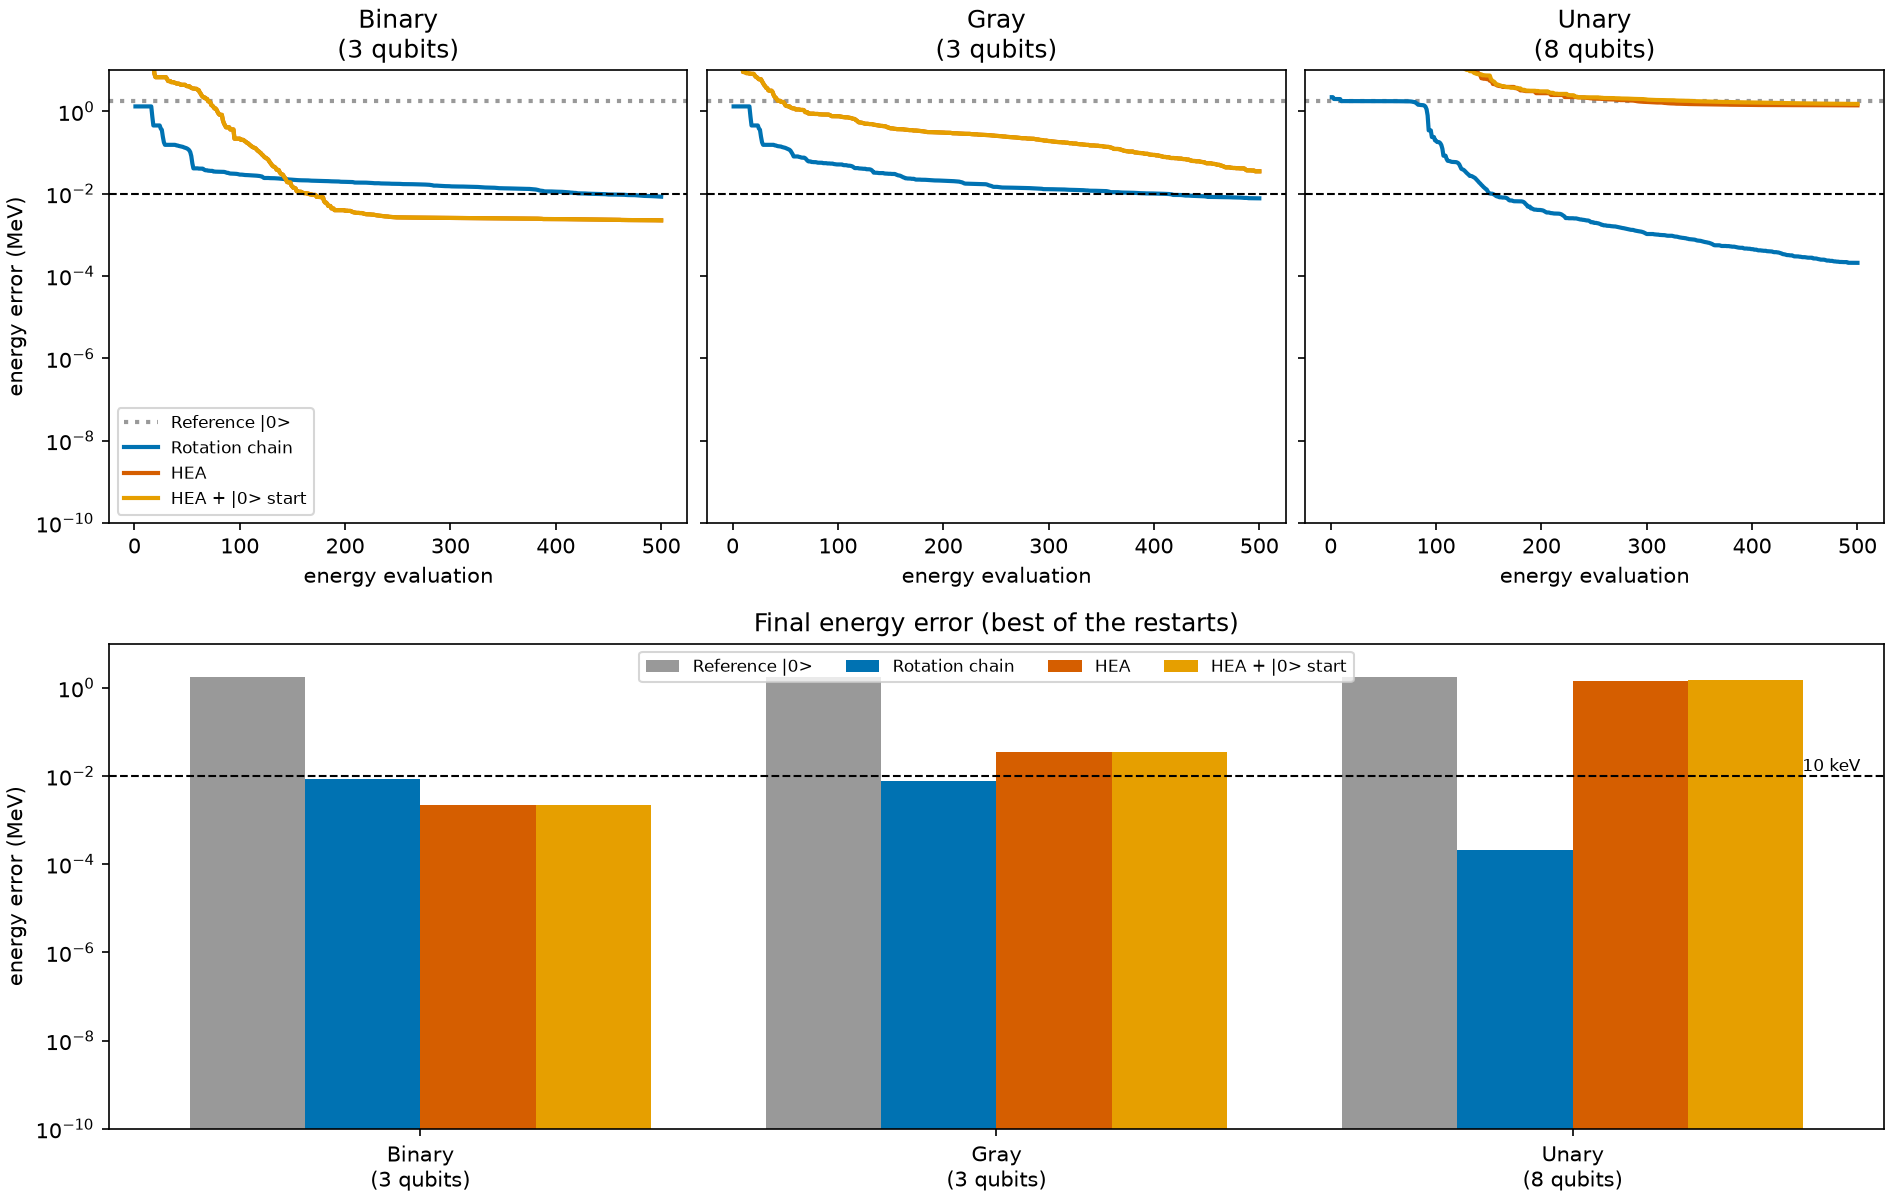

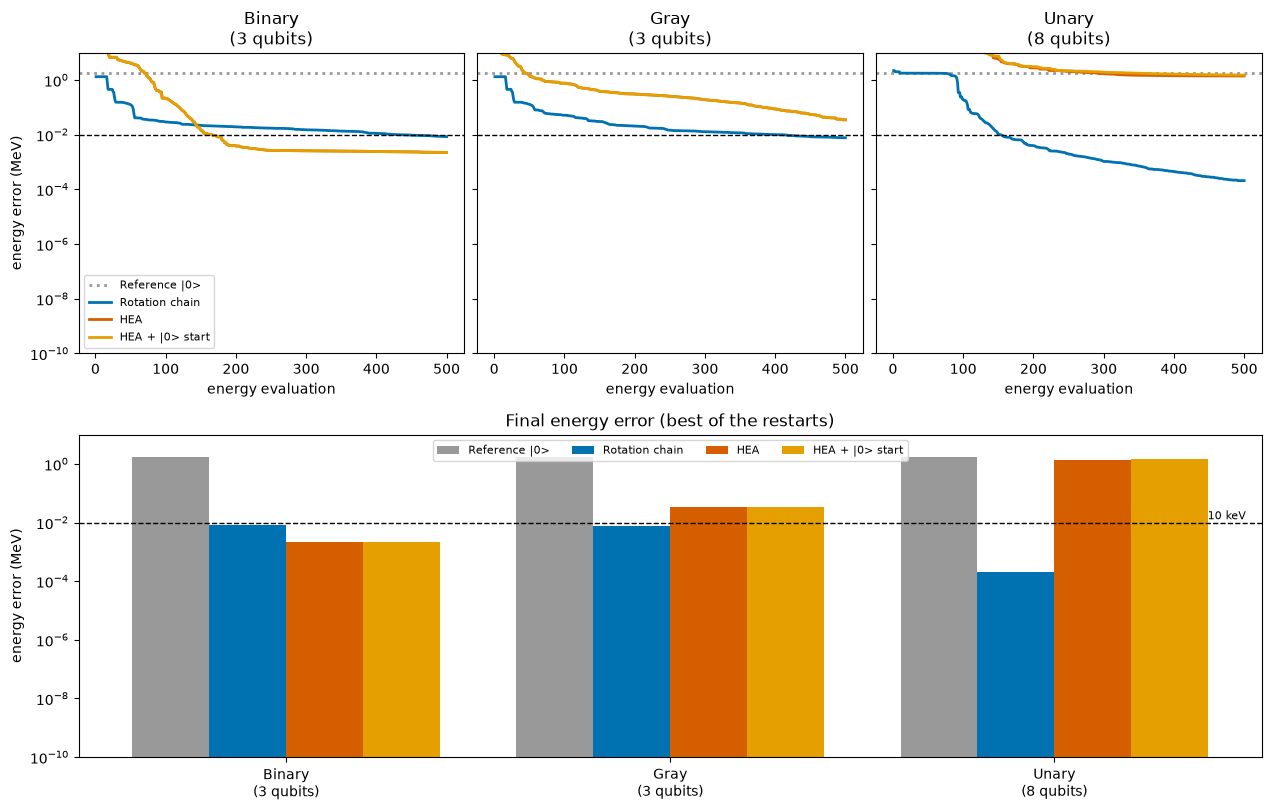

In [9]:
out = Path(tempfile.gettempdir()) / "deuteron_result.png"
analysis.analyze(data, out)
Image(out)

## Reading the results

*(Numbers below are for `n_states = 8`, `seed = 1`, `maxiter = 500`; yours will vary a little with the seed.)*

- **`ref` (gray)** sits about 1.8 MeV above the answer in every mapping. It never improves because it has no angles. The error is about 80% of the binding energy.
- **`rot` (blue)** reaches the exact energy in every mapping, within 10 keV. Its error keeps falling slowly with more evaluations, because COBYLA takes small steps along a long, narrow valley, not because the ansatz is short of angles. The mapping changes the circuit cost much more than the result: 68, 50 and 28 CX gates for binary, Gray and unary.
- **`hea` and `hea_ref` (oranges)** depend on the mapping. On the 3-qubit binary and Gray forms they come close (a few keV in binary, tens of keV in Gray): every state of the register is an oscillator state, and the 9 angles are about as many as the 7 that `rot` needs. In binary they match `rot` with 4 CX gates instead of 68. On the **8-qubit unary** form they fail: the search covers 256 states, 248 of them meaningless, and the error stays at 1.4 to 1.5 MeV, little better than `ref`. More qubits means a larger, flatter landscape and a budget that runs out.

**Lesson:** the mapping and the ansatz are chosen together. A compact mapping lets a generic ansatz succeed. A problem-aware ansatz succeeds with any mapping, at the price of a deeper circuit.

## Growing the basis

So far $N$ was fixed. The point of the encoding is that $N$ can grow cheaply: each doubling adds one qubit in the binary mapping. We run VQE with the `rot` ansatz for $N = 2, 4, 8, 16$ and compare with the exact curve, the infinite-basis value and the measurement. The Hamiltonian, $\hbar\omega$ and $V_0$ are the same throughout, so the only thing that changes is how well the wave function is resolved.

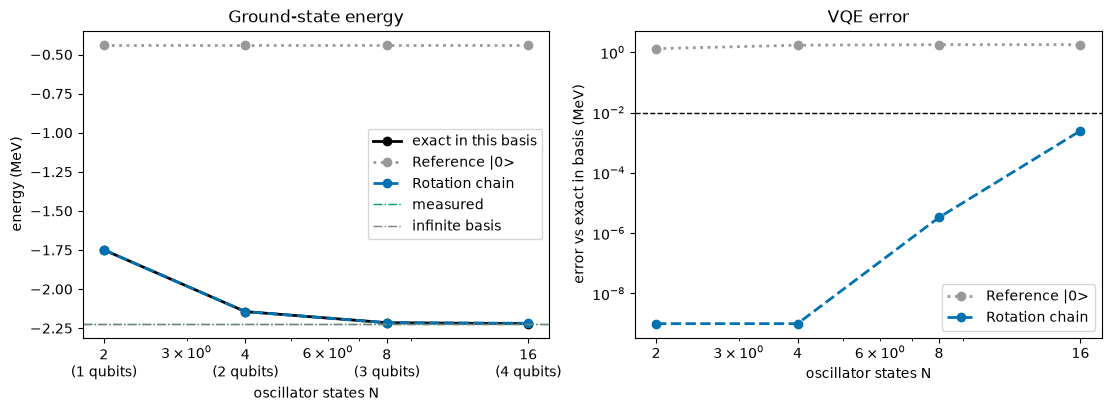

N =  2: exact -1.7492 MeV, VQE -1.7492 MeV, binding energy 1.7492 MeV
N =  4: exact -2.1440 MeV, VQE -2.1440 MeV, binding energy 2.1440 MeV
N =  8: exact -2.2150 MeV, VQE -2.2150 MeV, binding energy 2.2150 MeV
N = 16: exact -2.2211 MeV, VQE -2.2186 MeV, binding energy 2.2186 MeV


In [10]:
backend, estimator, session = execution.get_primitives(backend_name)
sizes = [2, 4, 8, 16]
curves = {"exact": [], "ref": [], "rot": []}
for n in sizes:
    ex = ops.exact_energies(n)
    curves["exact"].append(ex["exact"])
    curves["ref"].append(ex["ref"])
    rec = execution.optimize(
        n, "binary", "rot", estimator, backend, reps, starts=2, shots=shots, maxiter=1500
    )
    curves["rot"].append(rec["energy"])
if session is not None:
    session.close()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
style = {"exact": ("black", "-"), "ref": ("#999999", ":"), "rot": ("#0072B2", "--")}
labels = {"exact": "exact in this basis", "ref": enc.LABELS["ref"], "rot": enc.LABELS["rot"]}
for k, (color, ls) in style.items():
    ax1.plot(sizes, curves[k], color=color, ls=ls, lw=2, marker="o", label=labels[k])
    if k != "exact":
        err = np.maximum(np.array(curves[k]) - np.array(curves["exact"]), 1e-9)
        ax2.plot(sizes, err, color=color, ls=ls, lw=2, marker="o", label=labels[k])
ax1.axhline(ops.EXPERIMENT, color="#009E73", ls="-.", lw=1, label="measured")
ax1.axhline(ex["converged"], color="gray", ls="-.", lw=1, label="infinite basis")
ax1.set(xscale="log", xlabel="oscillator states N", ylabel="energy (MeV)", title="Ground-state energy")
ax1.set_xticks(sizes, [f"{n}\n({int(np.log2(n))} qubits)" for n in sizes])
ax1.legend()
ax2.axhline(analysis.TOLERANCE, color="black", ls="--", lw=1)
ax2.set(xscale="log", yscale="log", xlabel="oscillator states N", ylabel="error vs exact in basis (MeV)", title="VQE error")
ax2.set_xticks(sizes, [str(n) for n in sizes])
ax2.legend()
plt.show()

for n, e, r in zip(sizes, curves["exact"], curves["rot"]):
    print(f"N = {n:>2}: exact {e:.4f} MeV, VQE {r:.4f} MeV, binding energy {-r:.4f} MeV")

## Stop and think: what did the basis scan show?

1. **The truncation error falls fast.** The exact energy moves from $-1.75$ MeV at $N=2$ to $-2.22$ MeV at $N=16$. By $N=8$ the truncation error (6 keV) is already about as small as the gap between the contact model and the measurement (3 keV). More qubits would not improve the physics, only the numerics.
2. **The VQE error is a separate matter.** It does not shrink with $N$ (the $N=16$ run ends a few keV above the exact curve). Each new state adds an angle to `rot` and a longer circuit, and the optimizer has more to do within the same budget. A better optimizer or a better starting point would help here, not a better Hamiltonian.
3. **Two different errors.** The distance from the exact curve to the measured value is a **modeling error** (the Hamiltonian is not exactly the deuteron). The distance from VQE to the exact curve is a **computational error** (the circuit and the optimizer did not find the minimum). Keeping them apart tells you what to fix.
4. **Everything here is noiseless and exact.** Set `shots = 4096` and rerun Step 3: the optimizer now sees noisy energies. The standard error is $1/\sqrt{4096}\approx 0.016$ MeV for this scale of Hamiltonian, larger than our 10 keV target, so it cannot resolve the final digits. Getting below it needs many more shots, and noise from gates grows with circuit depth, so the shallow `hea` and the deeper `rot` trade places.

## What to try next

1. Change `seed` in Step 3 (add `seed=2` to `execution.run`) and see which `hea` runs converge. Raise `maxiter` or `starts`: does the mapping ranking change?
2. Try `n_states = 4` and `n_states = 16`. How does the unary mapping scale? What is the largest $N$ for which the simulator can still run it?
3. Set `reps = 1` or `reps = 4`. How does the number of angles trade against reliability in the binary and unary mappings?
4. Set `shots = 1000` and look at the final error. Which ansatzes survive sampling noise?
5. Run only a subset from the command line, for example `python deuteron/main.py --mappings binary gray --ansatzes rot hea --states 16`.
6. Change `V0` in `ops.py` and find the value that gives the measured $-2.2246$ MeV in the infinite basis. This is how the model is **fitted**: the strength of the interaction is tuned to one measurement, then used to predict others.
7. Add an ansatz of your own to `encoding.py`, for example a single $R_Y$ on each qubit followed by a CX ladder. Is that enough to reach the exact energy at $N=4$?
8. The same recipe (build $H$, choose a mapping and an ansatz, optimize) works for any small quantum system. Compare the search over bitstrings in the TSP notebook with the search over states here: what plays the role of the "penalty" in each?